## 02. Creating model for Ryanair
  

In [1]:
# Import necessary libraries
import pandas as pd
from datetime import timedelta, datetime
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt

import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, r2_score, make_scorer, f1_score,  roc_auc_score, classification_report


In [2]:
# Load prepared dataset
loaded_data = pd.read_csv('data.csv')
print(loaded_data.columns)

Index(['itinerary_id', 'departure_date', 'region_from', 'region_to',
       'flight_number', 'airline_name', 'operator', 'aircraft', 'src', 'dst',
       'travel_time', 'seat_pitch_type', 'emissions', 'price',
       'days_to_departure', 'is_weekend', 'dep_dayofweek', 'dep_month',
       'dep_dayofyear', 'dep_dayofmonth', 'dep_year', 'season', 'dep_hour_bin',
       'arr_hour_bin', 'price_hour_bin', 'distance', 'punctuality',
       'flights_per_week'],
      dtype='object')


## Feature Engineering & Target Variable Creation

### 1. Data Preparation
- Sort data by itinerary and departure days
- Create route keys for price comparison
- Calculate route-level price statistics (15th and 85th percentiles)

### 2. Price Position Features
- Calculate relative price position within route price range
- Create price comparison metrics vs route maximum
- Generate historical price volatility indicators

### 3. Target Variable Generation (Label Creation)
- Define "should wait" logic based on:
  - Days to departure thresholds (3-7, 8-20, 21+ days)
  - Required savings ratios (20%, 15%, 5%)
  - Price difference multipliers (1.15x, 1.10x, 1.05x)

### 4. Time-Based Feature Engineering
- Create urgency score (inverse of days to departure)
- Generate booking timing categories (advance vs last-minute)
- Build interaction features (price position × days)

### 5. Price Trend Features
- Calculate previous price and price differences
- Generate price trend slopes using gradient analysis
- Create historical price change indicators

### 6. Final Processing
- Handle duplicate combinations, NaN values
- Encode categorical features
- Spliting into test and train datasets

### Route-based features and labels are constructed from the full dataset to simulate the realistic availability of route-level pricing context! However they may bring some over generalization as it influenced by price that may not be known at prediction time. But I see this approach more reasonable for real-world scenario where we have access to price bounds calculated within one full year

In [3]:
def encode_categorical_features(data: pd.DataFrame, categorical_cols: list) -> tuple[pd.DataFrame, dict]:
    """
    Encode categorical variables using LabelEncoder.
    
    :param data: DataFrame to encode
    :param categorical_cols: List of categorical column names
    :return: Tuple of (encoded_data, encoders_dict)
    """
    data = data.copy()
    encoders = {}
    
    for col in categorical_cols:
        if col in data.columns:
            le = LabelEncoder()
            data[col] = le.fit_transform(data[col].astype(str))
            encoders[col] = le
    
    return data, encoders


def split_by_itinerary(data: pd.DataFrame, train_ratio: float = 0.8) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Split data by itinerary_id to ensure no data leakage.
    
    :param data: DataFrame to split
    :param train_ratio: Ratio of itineraries for training
    :return: Tuple of (train_data, test_data)
    """
    unique_itineraries = data['itinerary_id'].unique()
    train_size = int(train_ratio * len(unique_itineraries))
    
    train_itineraries = unique_itineraries[:train_size]
    
    train_data = data[data['itinerary_id'].isin(train_itineraries)]
    test_data = data[~data['itinerary_id'].isin(train_itineraries)]
    
    return train_data, test_data


def prepare_features_and_target(data: pd.DataFrame, target: str) -> tuple[pd.DataFrame, pd.Series]:
    """
    Prepare features (X) and target (y) by dropping unnecessary columns.
    
    :param data: DataFrame with all data
    :param target: Target column name
    :return: Tuple of (features, target)
    """

    
    data = data.loc[: ,['label', 'price', 'prev_price', 'prev_price_diff', 'trend_slope', 'days_to_departure', 'dep_month', 'dep_dayofyear', 'region_from', 'region_to', 'flights_per_week',
                        'route_max_price', 'route_min_price', 'price_vs_route_max', 
                        'price_position', 'price_position_x_days', 
                        'urgency_score',],]
    data = data.dropna()

    X = data.drop(target, axis=1)
    y = data[target]
    
    return X, y


def prepare_data(loaded_data: pd.DataFrame, target: str) -> tuple[pd.DataFrame, pd.Series, pd.DataFrame, pd.Series, pd.DataFrame, pd.Series, dict]:
    """
    Main function to prepare data for machine learning.
    
    :param loaded_data: Raw DataFrame
    :param target: Target column name
    :return: Tuple of (X, y, X_train, y_train, X_test, y_test, encoders)
    """
    data = loaded_data.copy()
    print(f"Initial data shape: {data.shape}")
    # Define categorical columns
    categorical_cols = [
        'flight_number', 'region_from', 'region_to',  
        'dep_hour_bin', 'arr_hour_bin', 'price_hour_bin', 'days_bin'
    ]
    
    # Step 1: Encode categorical variables
    data, encoders = encode_categorical_features(data, categorical_cols)
    
    # Step 2: Split by itinerary to avoid data leakage
    train_data, test_data = split_by_itinerary(data, train_ratio=0.8)
    

    # Step 3: Prepare features and target for full dataset
    X, y = prepare_features_and_target(data, target)
    
    # Step 4: Prepare features and target for train/test splits
    X_train, y_train = prepare_features_and_target(train_data, target)
    X_test, y_test = prepare_features_and_target(test_data, target)
    
    return X, y, X_train, y_train, X_test, y_test, encoders


##  Target Label Logic (should_wait):

  The function applies different waiting criteria based on departure proximity:
  
  - **3-7 days**: Wait if savings >15% AND current price >115% of future minimum
  - **8-20 days**: Wait if savings >10% AND current price >110% of future minimum  
  - **21+ days**: Wait if savings >5% AND current price >105% of future minimum
  
  Additional constraints:
  - Minimum absolute savings of €5 required
  - No waiting recommended if price_position < -0.1 (already very cheap)



In [4]:
def price_will_go_down(df, sample_max = None, sample_min = None):
    
    # Sort by flight_id and days_to_departure and set route_key
    df = df.sort_values(['itinerary_id', 'days_to_departure'], ascending=[True, False])
    df['route_key'] = df['src'].astype(str) + '_' + df['dst'].astype(str) + '_' + df['dep_month'].astype(str)

    # Group by route_key to calculate route statistics
    if sample_max is None:
        df['route_min_price'] = df.groupby('route_key')['price'].transform(lambda x: x.quantile(0.15))
        df['route_max_price'] = df.groupby('route_key')['price'].transform(lambda x: x.quantile(0.85))
    else:
        df['route_max_price'] = sample_max
        df['route_min_price'] = sample_min

    df['historical_route_price_std'] = df.groupby(['src', 'dst'])['price'].transform('std')
    df['price_vs_route_max'] = df['price'] / df['route_max_price']
    df['price_range'] = df['route_max_price'] - df['route_min_price']
    df['price_position'] = (df['price'] - df['route_min_price']) / df['price_range']
    df['price_position'] = df['price_position'].fillna(0.5)

    """# --- Price Category Bucketing ---
    bins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.1]
    labels = [0, 1, 2, 3, 4]
    df['price_category'] = pd.cut(df['price_position'], bins=bins, labels=labels, include_lowest=True).astype(int)
    """
    
    # --- Future Price Calculation ---
    df['min_future_price'] = df.groupby('itinerary_id')['price'].transform(
        lambda x: x[::-1].cummin().shift(1)[::-1]
    )
    

    
    def should_wait(row):

        if pd.isna(row['min_future_price']):
            return 0
        
        min_abs_savings = 5  # Minimum absolute savings to consider waiting

        days = row['days_to_departure']
        current_price = row['price']
        min_future_price = row['min_future_price']
        abs_savings = current_price - min_future_price
        savings_ratio = (row['price'] - row['min_future_price']) / row['price']

        # If price is significantly lower than min_price there is no point in waiting
        if row['price_position'] < -0.1:
            return 0
        if abs_savings < min_abs_savings:
            return 0

        if 3 <= days <= 7:
            return int(savings_ratio > 0.15 and row['price'] > row['min_future_price'] * 1.15)
        if 8 <= days <= 20:
            return int(savings_ratio > 0.10 and row['price'] > row['min_future_price'] * 1.10)
        if days >= 21:
            return int(savings_ratio > 0.05 and row['price'] > row['min_future_price'] * 1.05)
        return 0

        
    df['label'] = df.apply(should_wait, axis=1)
    
    # Interaction features with days_to_departure
    df['price_position_x_days'] = df['price_position'] * df['days_to_departure']
    #df['price_category_x_days'] = df['price_category'] * df['days_to_departure']
    
    # Time urgency features
    df['urgency_score'] = 1 / (df['days_to_departure'] + 1)  # Higher when closer to departure
    df['advance_booking'] = (df['days_to_departure'] > 30).astype(int)
    df['last_minute'] = (df['days_to_departure'] <= 7).astype(int)
    """    
    # Price volatility by days remaining
    df['price_volatility_window'] = df.groupby('flight_number')['price'].transform(
        lambda x: x.rolling(window=min(5, len(x)), min_periods=1).std()
    )
    """

    # Previous price difference
    df['prev_price'] = df.groupby('itinerary_id')['price'].shift(1)
    df['prev_price_diff'] = df['price'] - df['prev_price']
    df['trend_slope'] = df.groupby('itinerary_id')['price'].transform(
        lambda x: pd.Series(np.gradient(x), index=x.index))
    #df[]

    # --- Clean-up ---
    df = df.dropna(subset=['min_future_price'])  # final price can't be predicted
    df = df.drop_duplicates(subset=['itinerary_id', 'days_to_departure'], keep='last')

    return df

In [5]:
df = price_will_go_down(loaded_data)
X, y, X_train, y_train, X_test, y_test, encoders = prepare_data(df, 'label')


Initial data shape: (50499, 44)


## Model Training & Configuration

### XGBoost Classifier Setup
- Applied RandomizedSearchCV: 
    - Conservative learning parameters to prevent overfitting
    - Heavy regularization (L1/L2) to reduce overconfidence
    - Sample weighting strategy favoring closer departure dates
- Added monotonic constraints
- Sample weights to deal with class inbalance 


In [96]:
X_train.head()

,price,prev_price,prev_price_diff,trend_slope,days_to_departure,dep_month,dep_dayofyear,region_from,region_to,flights_per_week,route_max_price,route_min_price,price_vs_route_max,price_position,price_position_x_days,urgency_score
54992,81.37,43.47,37.90,16.66,35,8,218,2,4,34,143.8625,55.7355,0.565610,0.290881,10.180847,0.027778
54993,76.79,81.37,-4.58,-2.29,31,8,218,2,4,34,143.8625,55.7355,0.533774,0.238911,7.406238,0.031250
54994,76.79,76.79,0.00,-1.40,30,8,218,2,4,34,143.8625,55.7355,0.533774,0.238911,7.167327,0.032258
54995,73.99,76.79,-2.80,-1.40,28,8,218,2,4,34,143.8625,55.7355,0.514311,0.207139,5.799880,0.034483
54996,73.99,73.99,0.00,0.00,26,8,218,2,4,34,143.8625,55.7355,0.514311,0.207139,5.385603,0.037037


In [6]:
param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [5, 7],
    'min_child_weight': [5,8,10],
    'reg_alpha': [0.8, 1.0,],
    'reg_lambda': [0.3, 0.5, 0.7],
    'gamma': [0.2, 0.5],
    'subsample': [0.6, 0.7],
    'colsample_bytree': [0.6, 0.7],
    'n_estimators': [1000, 1200],

     # 1. Tree structure parameters
    'max_delta_step': [0, 1, 2],  # Helps with imbalanced classes
    'scale_pos_weight': [1, 2],   # Balance positive/negative classes automatically
    
    # 2. Feature sampling parameters
    #'colsample_bylevel': [0.6, 0.8, 1.0],    # Column sampling per tree level
    #'colsample_bynode': [0.6, 0.8, 1.0],     # Column sampling per tree node
    
    # 3. Learning control
    #'max_leaves': [0, 31, 63, 127],           # Limit number of leaves (0 = no limit)
    #'grow_policy': ['depthwise', 'lossguide'],

}

def create_monotonic_constraints(feature_names):
    """
    Create monotonic constraints based on flight pricing domain knowledge.
    Returns dict where values are: 1 (increasing), -1 (decreasing), 0 (no constraint)
    """
    constraints = {}
    
    for feature in feature_names:
        if 'days_to_departure' in feature:
            constraints[feature] = -1  # Closer to departure = higher urgency to buy
        elif 'urgency_score' in feature:
            constraints[feature] = 1   # Higher urgency = more likely to buy
        elif 'price_position' in feature and 'x_days' not in feature:
            constraints[feature] = 1   # Higher price position = more likely to wait
        elif 'route_min_price' in feature:
            constraints[feature] = -1  # Higher baseline price = less likely to wait
        else:
            constraints[feature] = 0   # No constraint
    
    return constraints

# Apply monotonic constraints
monotonic_constraints = create_monotonic_constraints(X_train.columns)
print("Monotonic constraints:")
for feature, constraint in monotonic_constraints.items():
    if constraint != 0:
        direction = "↗ Increasing" if constraint == 1 else "↘ Decreasing"
        print(f"  {feature}: {direction}")

Monotonic constraints:
  days_to_departure: ↘ Decreasing
  route_min_price: ↘ Decreasing
  price_position: ↗ Increasing
  urgency_score: ↗ Increasing


In [7]:
base_model = xgb.XGBClassifier(
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
    # Convert into a list
    monotonic_constraints = [monotonic_constraints.get(col, 0) for col in X_train.columns]
)

scoring = {
    'roc_auc': 'roc_auc',
    'f1_macro': 'f1_macro',
    'class0_f1': make_scorer(f1_score, pos_label=0),
    'class1_f1': make_scorer(f1_score, pos_label=1)
}

def run_grid_search():

    print("Starting grid search...")
    start_time  = datetime.now()

    grid_search = RandomizedSearchCV(
        estimator=base_model,
        param_distributions=param_grid,
        n_iter=100,
        scoring='accuracy',
        refit='f1_macro',  
        cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
        verbose=2,
        n_jobs=-1,
        random_state=42,
        return_train_score=True
    )    

    grid_search.fit(X_train, y_train, sample_weight=1/(X_train['days_to_departure'] + 1))

    end_time = datetime.now()
    print(f"Grid search completed in {end_time - start_time}")

    return grid_search

grid_result = run_grid_search()

Starting grid search...
Fitting 3 folds for each of 100 candidates, totalling 300 fits


KeyboardInterrupt: 

In [29]:
## Comprehensive Results Analysis

def analyze_metrics(grid_results):
    
    results_df = pd.DataFrame(grid_results.cv_results_)
    
    print("="*80)
    print("MULTI SEARCH RESULTS")
    print("="*80)
    
    # Best model by primary metric (business cost)
    print(f"Best F1 Score: {grid_results.best_score_:.4f}")
    print(f"Best Parameters:")
    for param, value in grid_results.best_params_.items():
        print(f"{param} = {value},")
    
    return results_df

# Analyze results
results_analysis = analyze_metrics(grid_result)

MULTI SEARCH RESULTS
Best F1 Score: 0.8893
Best Parameters:
subsample = 0.7,
scale_pos_weight = 1,
reg_lambda = 0.3,
reg_alpha = 0.8,
n_estimators = 1200,
min_child_weight = 5,
max_depth = 5,
max_delta_step = 2,
learning_rate = 0.1,
gamma = 0.2,
colsample_bytree = 0.7,


Sample weights range: 0.1000 to 1.0798
Days 1-7 get weight: 1.0293
Days 60+ get weight: 0.4939


f:\pet-projects\google-flight-scraper\myenv\Lib\site-packages\xgboost\training.py:183: UserWarning: [14:10:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "monotonic_constraints" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Feature importances:


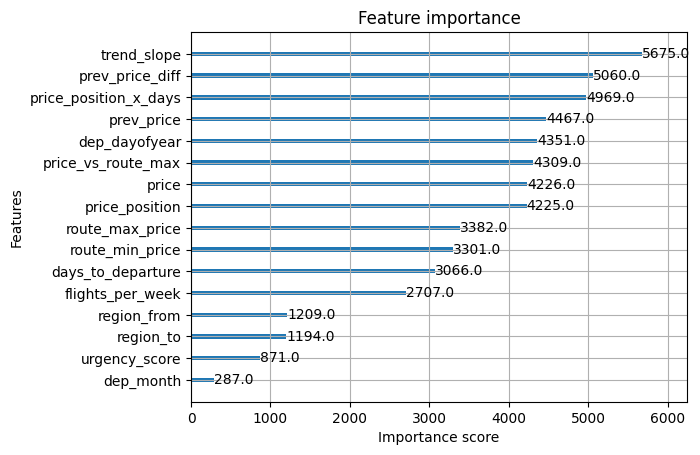

In [8]:
reg_basic = xgb.XGBClassifier(
    # Learning parameters - slower and more careful
    subsample = 0.7,
    scale_pos_weight = 1,
    reg_lambda = 0.3,
    reg_alpha = 0.8,
    n_estimators = 1200,
    min_child_weight = 5,
    max_depth = 7,
    max_delta_step = 2,
    learning_rate = 0.1,
    gamma = 0.2,
    colsample_bytree = 0.7,
    monotonic_constraints = [monotonic_constraints.get(col, 0) for col in X_train.columns]
)

max_days = X['days_to_departure'].max()
weights = (max_days - X.loc[X_train.index, 'days_to_departure']) / max_days
weights = weights + 0.1  


print(f"Sample weights range: {weights.min():.4f} to {weights.max():.4f}")
print(f"Days 1-7 get weight: {((max_days - 7) / max_days + 0.1):.4f}")
print(f"Days 60+ get weight: {((max_days - 60) / max_days + 0.1):.4f}")


reg_basic.fit(X_train, y_train,
        sample_weight=weights,
        verbose=True)

# Plot feature importances
print("Feature importances:")
xgb.plot_importance(reg_basic)
plt.show()

In [9]:
y_pred = reg_basic.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred))

y_pred_proba = reg_basic.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"ROC AUC Score: {roc_auc:.4f}")



Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.85      0.85      5471
           1       0.82      0.82      0.82      4385

    accuracy                           0.84      9856
   macro avg       0.84      0.84      0.84      9856
weighted avg       0.84      0.84      0.84      9856

ROC AUC Score: 0.9250


CLASS 0 (Price Won't Drop) Metrics:
Best F1 threshold: 0.650 (F1 = 0.859)
Best Recall threshold: 0.850 (Recall = 0.950)
Best Precision threshold: 0.100 (Precision = 0.936)


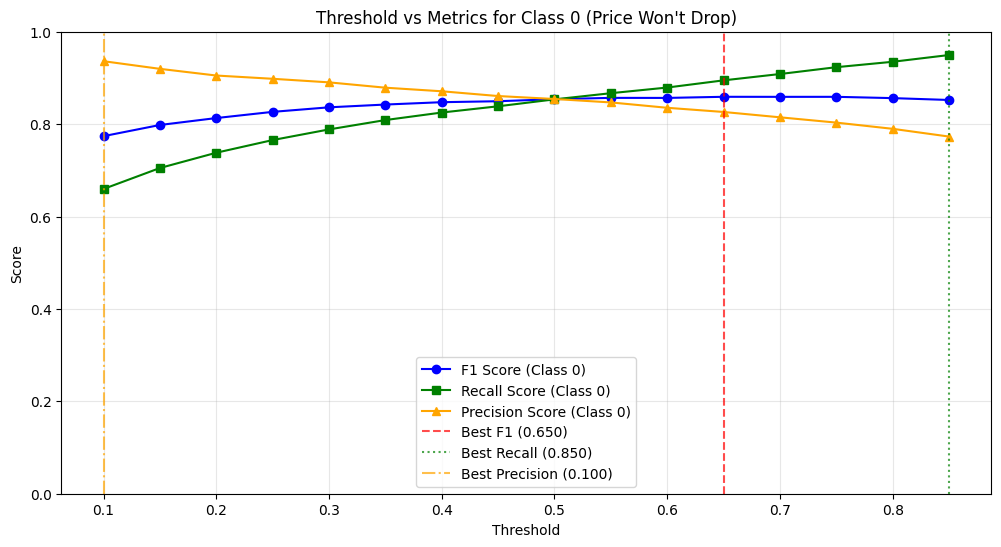

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

def find_best_threshold_class0(y_true, y_proba, metric='f1'):
    """
    Find the best threshold for a specific metric for CLASS 0.
    """
    thresholds = np.arange(0.1, 0.9, 0.05)
    scores = []
    
    for threshold in thresholds:
        y_pred = (y_proba >= threshold).astype(int)
        
        if metric == 'f1':
            score = f1_score(y_true, y_pred, pos_label=0)  # pos_label=0 for class 0
        elif metric == 'precision':
            score = precision_score(y_true, y_pred, pos_label=0)
        elif metric == 'recall':
            score = recall_score(y_true, y_pred, pos_label=0)
        
        scores.append(score)
    
    best_idx = np.argmax(scores)
    best_threshold = thresholds[best_idx]
    best_score = scores[best_idx]
    
    return best_threshold, best_score, thresholds, scores

# Get probabilities
y_pred_proba = reg_basic.predict_proba(X_test)[:, 1]

# Find best threshold for different metrics FOR CLASS 0
best_f1_threshold_c0, best_f1_score_c0, thresholds, f1_scores_c0 = find_best_threshold_class0(y_test, y_pred_proba, 'f1')
best_recall_threshold_c0, best_recall_score_c0, _, recall_scores_c0 = find_best_threshold_class0(y_test, y_pred_proba, 'recall')
best_precision_threshold_c0, best_precision_score_c0, _, precision_scores_c0 = find_best_threshold_class0(y_test, y_pred_proba, 'precision')

print(f"CLASS 0 (Price Won't Drop) Metrics:")
print(f"Best F1 threshold: {best_f1_threshold_c0:.3f} (F1 = {best_f1_score_c0:.3f})")
print(f"Best Recall threshold: {best_recall_threshold_c0:.3f} (Recall = {best_recall_score_c0:.3f})")
print(f"Best Precision threshold: {best_precision_threshold_c0:.3f} (Precision = {best_precision_score_c0:.3f})")

# Plot threshold vs metrics for CLASS 0
plt.figure(figsize=(12, 6))
plt.plot(thresholds, f1_scores_c0, label='F1 Score (Class 0)', marker='o', color='blue')
plt.plot(thresholds, recall_scores_c0, label='Recall Score (Class 0)', marker='s', color='green')
plt.plot(thresholds, precision_scores_c0, label='Precision Score (Class 0)', marker='^', color='orange')

plt.axvline(x=best_f1_threshold_c0, color='red', linestyle='--', alpha=0.7, 
           label=f'Best F1 ({best_f1_threshold_c0:.3f})')
plt.axvline(x=best_recall_threshold_c0, color='green', linestyle=':', alpha=0.7, 
           label=f'Best Recall ({best_recall_threshold_c0:.3f})')
plt.axvline(x=best_precision_threshold_c0, color='orange', linestyle='-.', alpha=0.7, 
           label=f'Best Precision ({best_precision_threshold_c0:.3f})')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Threshold vs Metrics for Class 0 (Price Won\'t Drop)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 1)
plt.show()

# Show comparison table
results_df = pd.DataFrame({
    'Threshold': thresholds,
    'F1_Class0': f1_scores_c0,
    'Recall_Class0': recall_scores_c0,
    'Precision_Class0': precision_scores_c0
})


Threshold: 0.5
Predictions distribution:
  Class 0 (price won't drop): 5466
  Class 1 (price will drop): 4390

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      5471
           1       0.82      0.82      0.82      4385

    accuracy                           0.84      9856
   macro avg       0.84      0.84      0.84      9856
weighted avg       0.84      0.84      0.84      9856



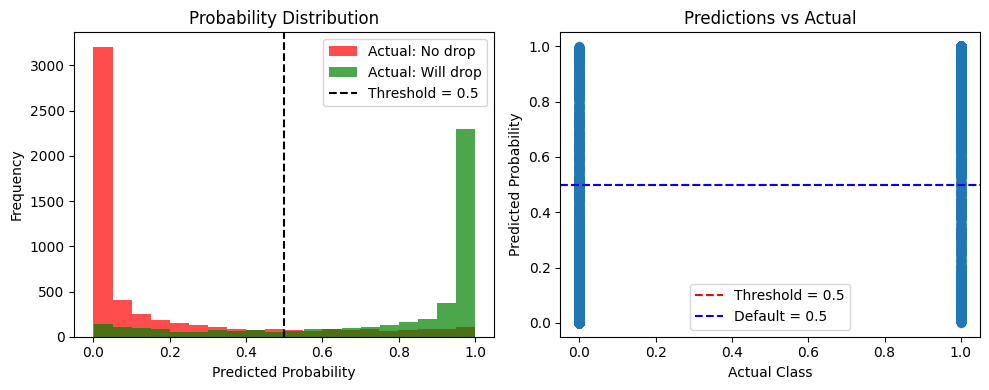


Predictions changed due to threshold: 0


In [77]:
def predict_with_custom_threshold(model, X_test, y_test, threshold=0.5, show_analysis=True):
    """
    Make predictions with custom threshold and show analysis.
    """
    # Get probabilities
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # Apply threshold
    y_pred = (y_pred_proba >= threshold).astype(int)
    
    if show_analysis:
        print(f"Threshold: {threshold}")
        print(f"Predictions distribution:")
        print(f"  Class 0 (price won't drop): {(y_pred == 0).sum()}")
        print(f"  Class 1 (price will drop): {(y_pred == 1).sum()}")
        print(f"\nClassification Report:")
        print(classification_report(y_test, y_pred))
        
        # Show probability distribution
        plt.figure(figsize=(10, 4))
        
        plt.subplot(1, 2, 1)
        plt.hist(y_pred_proba[y_test == 0], bins=20, alpha=0.7, label='Actual: No drop', color='red')
        plt.hist(y_pred_proba[y_test == 1], bins=20, alpha=0.7, label='Actual: Will drop', color='green')
        plt.axvline(x=threshold, color='black', linestyle='--', label=f'Threshold = {threshold}')
        plt.xlabel('Predicted Probability')
        plt.ylabel('Frequency')
        plt.title('Probability Distribution')
        plt.legend()
        
        plt.subplot(1, 2, 2)
        comparison_df = pd.DataFrame({
            'Actual': y_test.values, 
            'Predicted': y_pred,
            'Probability': y_pred_proba
        })
        
        # Show cases where we changed prediction due to threshold
        changed_predictions = comparison_df[
            ((comparison_df['Probability'] >= threshold) & (comparison_df['Probability'] < 0.5)) |
            ((comparison_df['Probability'] < threshold) & (comparison_df['Probability'] >= 0.5))
        ]
        
        plt.scatter(comparison_df['Actual'], comparison_df['Probability'], alpha=0.6)
        plt.axhline(y=threshold, color='red', linestyle='--', label=f'Threshold = {threshold}')
        plt.axhline(y=0.5, color='blue', linestyle='--', label='Default = 0.5')
        plt.xlabel('Actual Class')
        plt.ylabel('Predicted Probability')
        plt.title('Predictions vs Actual')
        plt.legend()
        
        plt.tight_layout()
        plt.show()
        
        print(f"\nPredictions changed due to threshold: {len(changed_predictions)}")
    
    return y_pred, y_pred_proba

# Usage
y_pred_custom, y_proba = predict_with_custom_threshold(reg_basic, X_test, y_test, threshold=0.50)

In [79]:
# Predicting test flight

def test_flight(date_time, src, dst, flight_number=None, distance=None):
    date, time = date_time.split(' ')
    date = datetime.strptime(date, '%Y-%m-%d')
    print(date)
    time = datetime.strptime(time, '%H:%M').time()
    # Example: create a test dictionary for a single flight
    flight_params = {
        'itinerary_id': f'{flight_number}-{date.strftime("%Y%m%d")}-{src}-{dst}',
        'flight_number': flight_number,
        'src': src,
        'dst': dst,
        'dep_month': date.month,
        'dep_dayofyear': date.timetuple().tm_yday,
        'is_weekend': 0 if date.weekday() <= 4 else 1,  # Saturday or Sunday
        'flights_per_week': 9,  # Example value, adjust as needed
        'distance': distance,  # example value, adjust as needed
        'region_from': encoders['region_from'].transform(['Baltics'])[0],
        'region_to': encoders['region_to'].transform(['Western'])[0],
    }
    


    test_flight = pd.read_csv(f'test_data/{flight_number}_actual.csv')
    test_rows = []
    for row in test_flight.itertuples(index=False):
        ft = flight_params.copy()
        ft['days_to_departure'] = row.Date
        ft['price'] = row.Price
        test_rows.append(ft)

    # Create DataFrame
    test_df = pd.DataFrame(test_rows)



    return test_df

test_flight = test_flight('2025-10-9 14:20', 'VNO', 'BCN', 'FR1787', distance=2260)

test_df = price_will_go_down(test_flight, 110, 40 )

X_test_flight, y_test_flight = prepare_features_and_target(test_df, 'label')




2025-10-09 00:00:00


In [93]:
from sklearn.calibration import CalibratedClassifierCV

cal = CalibratedClassifierCV(reg_basic, method="isotonic", cv=5)

cal.fit(X_train, y_train)
y_proba_cal = cal.predict_proba(X_test)[:,1]



f:\pet-projects\google-flight-scraper\myenv\Lib\site-packages\xgboost\training.py:183: UserWarning: [14:50:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "monotonic_constraints" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
f:\pet-projects\google-flight-scraper\myenv\Lib\site-packages\xgboost\training.py:183: UserWarning: [14:50:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "monotonic_constraints" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
f:\pet-projects\google-flight-scraper\myenv\Lib\site-packages\xgboost\training.py:183: UserWarning: [14:50:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "monotonic_constraints" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
f:\pet-projects\google-flight-scraper\myenv\Lib\site-packages\xgboost\training.py:183: UserWarning: [14:50:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\

In [94]:
# Strategy 4: Post-processing to reduce overconfident predictions
import numpy as np

def apply_confidence_penalty(probabilities, days_to_departure, price_position, t0=-0.3, k=10, cheap_penalty=0.6, cheap_cut=0.2):
    """
    Penalize overconfident predictions based on:
    - Cheap tickets
    - Time proximity to departure
    """

    probabilities = np.clip(probabilities, 1e-6, 1.0)

    # Penalty 1: If price is very low
    cheap_penalty = np.where(price_position < cheap_cut, 0.6, 1.0)

    # Penalty 2: Smooth time decay (sigmoid) - closer flights get heavier penalty
    time_penalty = 1 / (1 + np.exp(k * (days_to_departure - t0)))

    # Normalize time penalty to [0.5, 1.0] range to reduce effect
    time_penalty = 0.2 + 0.5 * time_penalty

    # Combined penalty
    penalty = cheap_penalty * time_penalty

    # Apply penalty by pushing confidence toward 0.5
    adjusted = 0.5 + (probabilities - 0.5) * penalty

    return np.clip(adjusted, 0, 1)

# Make conservative predictions
y_pred_conservative_raw = cal.predict_proba(X_test_flight)[:, 1]

# Apply confidence penalties
y_pred_conservative_adjusted = apply_confidence_penalty(
    y_pred_conservative_raw,
    X_test_flight['days_to_departure'].values,
    X_test_flight['price_position'].values,
    *(15, -0.6, 0.05, 0.2)
)

# Final predictions
y_pred_conservative_final = (y_pred_conservative_adjusted >= 0.5).astype(int)

print("Conservative Model y_test_flight:")
print(classification_report(y_test_flight, y_pred_conservative_final))

# Check for high-confidence false positives
conservative_comparison_df = pd.DataFrame({
    'Actual': y_test_flight.values, 
    'Predicted': y_pred_conservative_final,
    'Predicted_Raw': y_pred_conservative_raw,
    'Predicted_Adjusted': y_pred_conservative_adjusted,
    'price': X_test_flight['price'], 
}, index=y_test_flight.index)

# Check for remaining false positives
remaining_fps = conservative_comparison_df[
    (conservative_comparison_df['Actual'] == 0) & 
    (conservative_comparison_df['Predicted_Adjusted'] > 0.5)
]


print(f"\nRemaining high-confidence false positives: {len(remaining_fps)}")
if len(remaining_fps) > 0:
    print(remaining_fps.head(10))

print("Conservative Model y_test_flight:")
print(classification_report(y_test_flight, y_pred_conservative_final))

print(conservative_comparison_df.head(60))


Conservative Model y_test_flight:
              precision    recall  f1-score   support

           0       0.55      1.00      0.71        12
           1       1.00      0.79      0.88        47

    accuracy                           0.83        59
   macro avg       0.77      0.89      0.79        59
weighted avg       0.91      0.83      0.85        59


Remaining high-confidence false positives: 0
Conservative Model y_test_flight:
              precision    recall  f1-score   support

           0       0.55      1.00      0.71        12
           1       1.00      0.79      0.88        47

    accuracy                           0.83        59
   macro avg       0.77      0.89      0.79        59
weighted avg       0.91      0.83      0.85        59

    Actual  Predicted  Predicted_Raw  Predicted_Adjusted  price
1        1          1       0.881383            0.766968    122
2        1          1       0.997468            0.848228    108
3        1          1       0.625534    

In [92]:
y_test_pred_proba = reg_basic.predict_proba(X_test_flight)[:, 1]
comparison_df = pd.DataFrame({
    'Actual': y_test_flight,
    'Predicted': y_pred_conservative_final,
    'Probability': y_pred_conservative_adjusted,
    'days_to_departure': X_test_flight['days_to_departure'],
    'price': X_test_flight['price'],
})

print(comparison_df.head(60))

    Actual  Predicted  Probability  days_to_departure  price
1        1          1     0.843795                 61    122
2        1          1     0.849937                 60    108
3        1          1     0.743864                 59     74
4        1          1     0.849781                 58     74
5        0          0     0.186579                 57     54
6        1          1     0.680450                 56     66
7        1          1     0.671313                 55     69
8        1          1     0.700622                 54     73
9        1          1     0.724955                 53     90
10       1          1     0.839986                 52    122
11       1          1     0.842890                 51    122
12       1          1     0.849736                 50    108
13       1          1     0.649637                 49     87
14       1          1     0.689215                 48     87
15       1          1     0.791541                 47     91
16       1          1   